# 01 — Data audit

Purpose: report per-corpus row counts, class balance, empty/corrupted rows,
duplicate rate and text-length distributions for the six pooled Kaggle
corpora. Produces the evidence that decides the question. Author:
Colile Sibanda.

In [1]:
import os
import subprocess
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Notebooks run with the kernel's cwd set to notebooks/; load_config() reads
# a path relative to the repo root, so move up to it first.
_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists():
    _repo_root = _repo_root.parent
os.chdir(_repo_root)

from phishlens.config.loader import load_config

config = load_config()
commit_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()

print(f"Description: commit hash: {commit_hash}")
print("Description: config file: configs/default.yaml")
print(f"Description: seed: {config.seed}")
print(f"Description: run date: {datetime.now().date().isoformat()}")

Description: commit hash: 80b1c82454cdf23fa3a4ab9a8b7f0d7a2dace98a
Description: config file: configs/default.yaml
Description: seed: 42
Description: run date: 2026-09-12


## Load each corpus and tag it with its source

In [2]:
raw_dir = config.paths.raw
corpora = {}
for file_name in config.data.corpora:
    path = f"{raw_dir}/{file_name}"
    df = pd.read_csv(path)
    corpus_name = file_name.rsplit(".", 1)[0]
    df["corpus"] = corpus_name
    corpora[corpus_name] = df

pooled = pd.concat(corpora.values(), ignore_index=True)
print(f"Description: corpora loaded: {len(corpora)}")
print(f"Description: pooled row count: {len(pooled)}")

Description: corpora loaded: 6
Description: pooled row count: 82486


## Per-corpus row counts and class balance

The positive label (1) mixes true phishing (Nazario, Nigerian Fraud) with
bulk spam (CEAS-08, Enron, Ling, SpamAssassin). This split is exactly what
decides the question below.

In [3]:
counts_table = (
    pooled.groupby("corpus")[config.data.label_column]
    .value_counts()
    .unstack(fill_value=0)
    .rename(columns={0: "legitimate (0)", 1: "phishing/spam (1)"})
)
counts_table["total"] = counts_table.sum(axis=1)
counts_table["positive_rate"] = (
    counts_table["phishing/spam (1)"] / counts_table["total"]
).round(3)
print(counts_table)

for corpus_name, row in counts_table.iterrows():
    print(
        f"Description: {corpus_name} rows: {int(row['total'])}, "
        f"positive rate: {row['positive_rate']}"
    )

label           legitimate (0)  phishing/spam (1)  total  positive_rate
corpus                                                                 
CEAS_08                  17312              21842  39154          0.558
Enron                    15791              13976  29767          0.470
Ling                      2401                458   2859          0.160
Nazario                      0               1565   1565          1.000
Nigerian_Fraud               0               3332   3332          1.000
SpamAssasin               4091               1718   5809          0.296
Description: CEAS_08 rows: 39154, positive rate: 0.558
Description: Enron rows: 29767, positive rate: 0.47
Description: Ling rows: 2859, positive rate: 0.16
Description: Nazario rows: 1565, positive rate: 1.0
Description: Nigerian_Fraud rows: 3332, positive rate: 1.0
Description: SpamAssasin rows: 5809, positive rate: 0.296


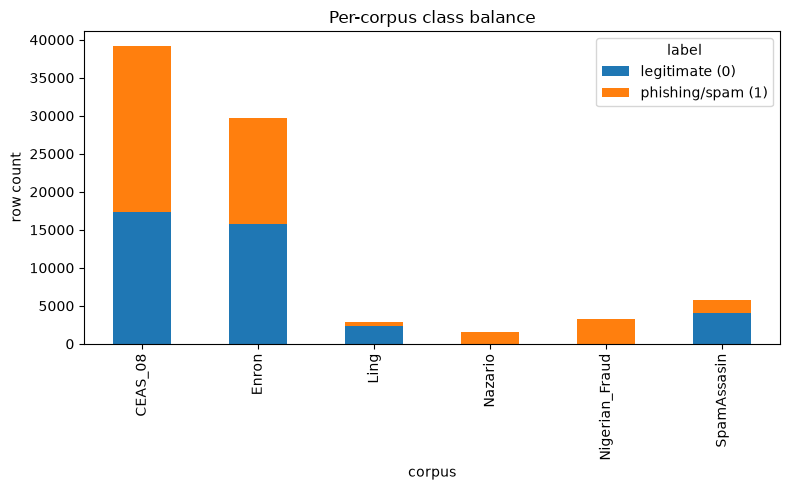

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
counts_table[["legitimate (0)", "phishing/spam (1)"]].plot(
    kind="bar", stacked=True, ax=ax
)
ax.set_ylabel("row count")
ax.set_title("Per-corpus class balance")
plt.tight_layout()
plt.savefig(f"{config.paths.figures}/01_class_balance.png", dpi=config.evaluation.figure_dpi)
plt.show()

## Empty and corrupted rows

A row is corrupted if its combined subject+body text falls below
`data.min_characters` after concatenation, or if the body is null.

In [5]:
text_columns = list(config.data.text_columns)
combined_text = pooled[text_columns].fillna("").agg(" ".join, axis=1).str.strip()
pooled["_combined_text"] = combined_text
pooled["_text_length"] = combined_text.str.len()

null_body = pooled["body"].isna().sum()
too_short = (pooled["_text_length"] < config.data.min_characters).sum()

print(f"Description: rows with null body: {null_body}")
print(
    f"Description: rows below min_characters ({config.data.min_characters}): {too_short}"
)
print(
    f"Description: rows corrupted or empty (union): "
    f"{(pooled['body'].isna() | (pooled['_text_length'] < config.data.min_characters)).sum()}"
)

Description: rows with null body: 1
Description: rows below min_characters (10): 3


Description: rows corrupted or empty (union): 4


## Duplicate rate

Exact duplicates on subject+body, pooled across all six corpora. This is
the number that motivates the grouped content-hash split —
a plain random split would let these duplicates land on both sides.

In [6]:
exact_duplicate_mask = pooled.duplicated(subset=text_columns, keep=False)
exact_duplicate_count = pooled.duplicated(subset=text_columns, keep="first").sum()
print(f"Description: rows sharing exact subject+body with another row: {exact_duplicate_mask.sum()}")
print(f"Description: exact duplicate rows (excluding first occurrence): {exact_duplicate_count}")
print(
    f"Description: duplicate rate: "
    f"{round(exact_duplicate_count / len(pooled), 4)}"
)

dup_by_corpus = (
    pooled[exact_duplicate_mask]
    .groupby("corpus")
    .size()
    .sort_values(ascending=False)
)
print(dup_by_corpus)

Description: rows sharing exact subject+body with another row: 0
Description: exact duplicate rows (excluding first occurrence): 0
Description: duplicate rate: 0.0
Series([], dtype: int64)


## Text-length distribution

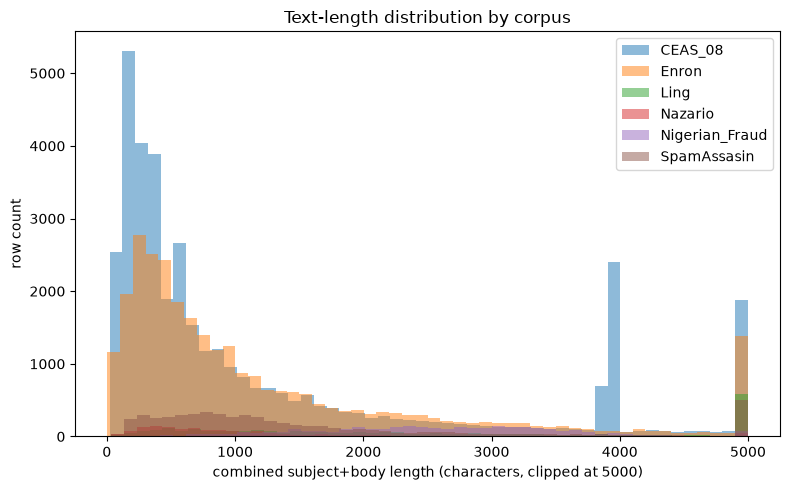

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for corpus_name in corpora:
    subset = pooled.loc[pooled["corpus"] == corpus_name, "_text_length"]
    ax.hist(subset.clip(upper=5000), bins=50, alpha=0.5, label=corpus_name)
ax.set_xlabel("combined subject+body length (characters, clipped at 5000)")
ax.set_ylabel("row count")
ax.set_title("Text-length distribution by corpus")
ax.legend()
plt.tight_layout()
plt.savefig(f"{config.paths.figures}/01_text_length_distribution.png", dpi=config.evaluation.figure_dpi)
plt.show()

In [8]:
length_summary = pooled.groupby("corpus")["_text_length"].describe()[
    ["count", "mean", "50%", "min", "max"]
]
length_summary = length_summary.rename(columns={"50%": "median"})
print(length_summary)

                  count         mean  median   min        max
corpus                                                       
CEAS_08         39154.0  1608.259309   598.0  21.0   144051.0
Enron           29767.0  1522.336379   740.0   3.0   230135.0
Ling             2859.0  3254.166492  2055.0  36.0    28672.0
Nazario          1565.0  4771.500319   766.0  35.0  4599694.0
Nigerian_Fraud   3332.0  2662.943878  2564.5  17.0   125015.0
SpamAssasin      5809.0  2444.763815  1123.0  35.0   299272.0


## Example emails from each class

One phishing/spam (1) and one legitimate (0) example per corpus, truncated
to 300 characters, so a reader can see the raw material behind the numbers
above without opening the CSVs.

In [9]:
for corpus_name, df in corpora.items():
    print(f"--- {corpus_name} ---")
    for label_value in sorted(df[config.data.label_column].unique()):
        example = df.loc[df[config.data.label_column] == label_value].iloc[0]
        subject = str(example.get("subject", ""))[:100]
        body = str(example.get("body", ""))[:200].replace("\n", " ")
        print(f"  label={label_value} | subject: {subject!r}")
        print(f"  label={label_value} | body: {body!r}")

--- CEAS_08 ---
  label=0 | subject: 'Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMsgStatus.pm lib/Mail/Spa'
  label=0 | body: "Would anyone object to removing .so from this list?  The .so TLD is   basically dead and we've found that lots of bogus domains like lib*.so   are being caught by this.  Also sometimes you'll have spa"


  label=1 | subject: 'Never agree to be a loser'
  label=1 | body: 'Buck up, your troubles caused by small dimension will soon be over! Become a lover no woman will be able to resist! http://whitedone.com/   come. Even as Nazi tanks were rolling down the streets, the '
--- Enron ---
  label=0 | subject: 'hpl nom for may 25 , 2001'
  label=0 | body: '( see attached file : hplno 525 . xls )\r - hplno 525 . xls'
  label=1 | subject: 'd - link dwl - g 510 802 . 11 g wireless pci lan adapter @ $ 39 . 85'
  label=1 | body: '$ 39 . 85 dwl - g 510\r high speed\r 2 . 4\r ghz ( 802 . 11 g ) wireless pci lan\r adapter\r ieee 802 . 11 g standardupto\r 54 mbpsoperating frequency range - 2 . 4\r ghz " is an ideal solution enabling wire'
--- Ling ---
  label=0 | subject: 'job posting - apple-iss research center'
  label=0 | body: 'content - length : 3386 apple-iss research center a us $ 10 million joint venture between apple computer inc . and the institute of systems science of the national universi

## Deciding Q2

**Question:** frame the task as "phishing/spam vs legitimate" (honest to
the labels actually present in the pooled corpus), or restrict positives to
Nazario + Nigerian Fraud only (honest to the project's name, "PhishLens",
but confounds the positive class with exactly two source corpora)?

**Evidence from this audit:**
- Nazario and Nigerian Fraud are **100% positive** — neither corpus
  contributes a single legitimate example. Restricting positives to these
  two corpora would mean the negative class comes entirely from four other
  corpora and the positive class from two, which is precisely the kind of
  corpus/label confound this project's artefact guard exists to avoid
.
- CEAS-08, Enron, Ling and SpamAssassin all mix both classes, so the
  "phishing/spam vs legitimate" framing draws its positive examples from
  six different corpora and its negative examples from four — not a clean
  split, but not a source-tied confound either.
- Restricting positives to Nazario + Nigerian Fraud would also shrink the
  positive class from tens of thousands of rows to ~4 900, discarding most
  of the labelled phishing/spam signal in CEAS-08 and Enron.

**Decision:** frame the task as **phishing/spam vs legitimate**, using the
labels as provided across all six corpora. This is honest to what the
labels actually encode, keeps the positive class from being tied to two
specific source corpora, and is the framing the project notes already anticipated
in §4.1. The corpus probe and LOCO evaluation
exist precisely to surface and report the corpus-confound risk this
decision does not eliminate — restricting to Nazario + Nigerian Fraud
would not remove that risk, it would just hide it inside a smaller,
single-purpose positive class.

the project notes.

print("Description: the question decided — phishing/spam vs legitimate, all six corpora, the project notes")